### Задача 14

Сравните качества визуализации данных с точки зрения отделения классов для методов PCA и  TSNE для набора данных MNIST.

In [22]:
import time
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

np.random.seed(42)
warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")

#### Данные + EDA

In [23]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X, y = mnist.data, mnist.target.astype(int)

In [24]:
display(pd.DataFrame(data=mnist.data))
print(mnist.DESCR)

,0,1,2,3,4,5,6,7,8,9,...,774,775,776,777,778,779,780,781,782,783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  
**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  
**Please cite**:  

The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  

It is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 image b

In [ ]:
# print(X[0].reshape(28, 28))

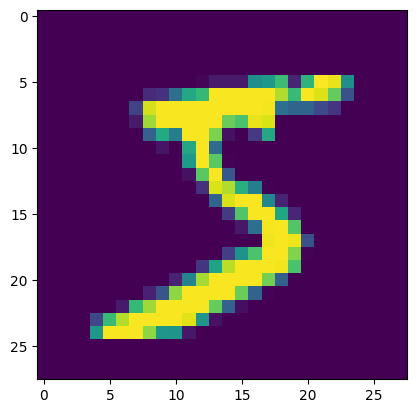

In [25]:
plt.imshow(X[0].reshape(28, 28))

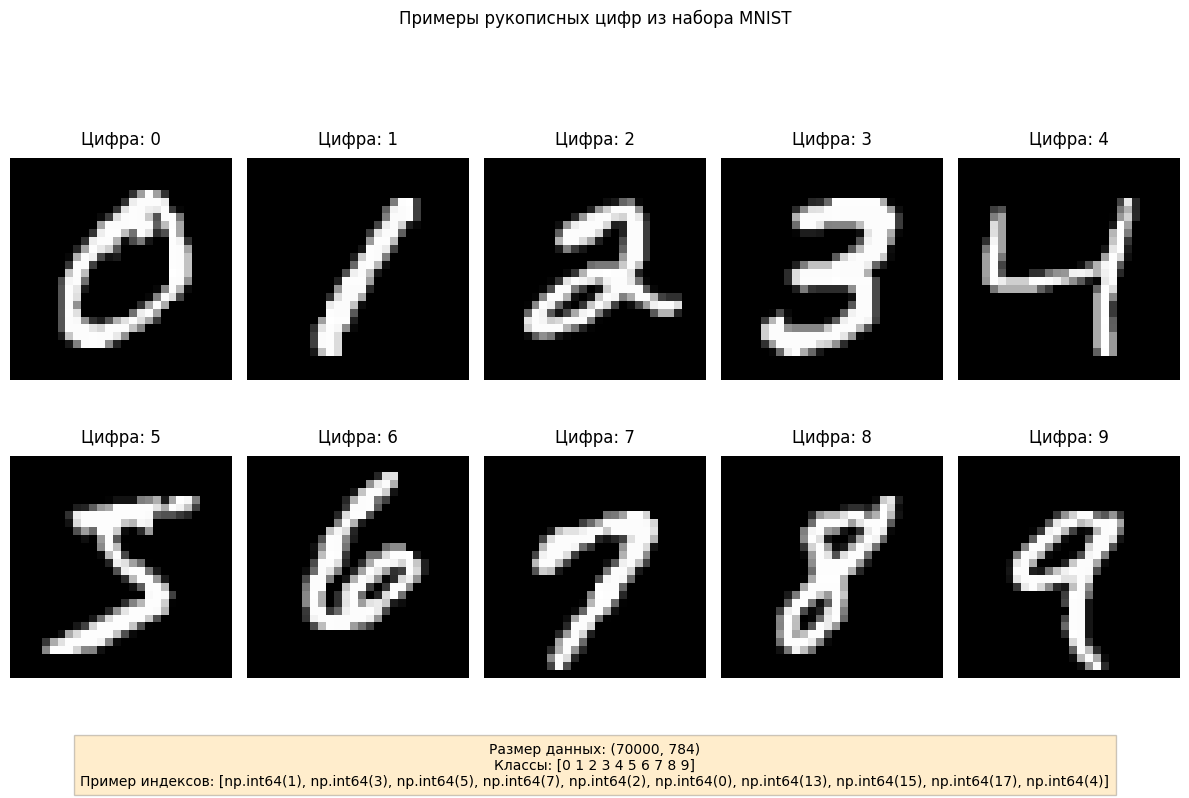

In [26]:
plt.figure(figsize=(12, 8))
plt.suptitle('Примеры рукописных цифр из набора MNIST')

unique_digits = np.arange(10)
selected_indices = []

for digit in unique_digits:
    idx = np.where(y == digit)[0][0]
    selected_indices.append(idx)
    plt.subplot(2, 5, digit + 1)
    img = X[idx].reshape(28, 28)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title(f'Цифра: {digit}', fontsize=12, pad=10)
    plt.axis('off')

plt.figtext(0.5, 0.01,
            f'Размер данных: {X.shape}\n'
            f'Классы: {np.unique(y)}\n'
            f'Пример индексов: {selected_indices}',
            ha="center",
            fontsize=10,
            bbox={"facecolor":"orange", "alpha":0.2, "pad":5})

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [27]:
print(pd.DataFrame(data=y).value_counts().sort_index())

0
0    6903
1    7877
2    6990
3    7141
4    6824
5    6313
6    6876
7    7293
8    6825
9    6958
Name: count, dtype: int64


/tmp/ipykernel_3049/2172572036.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette='viridis')


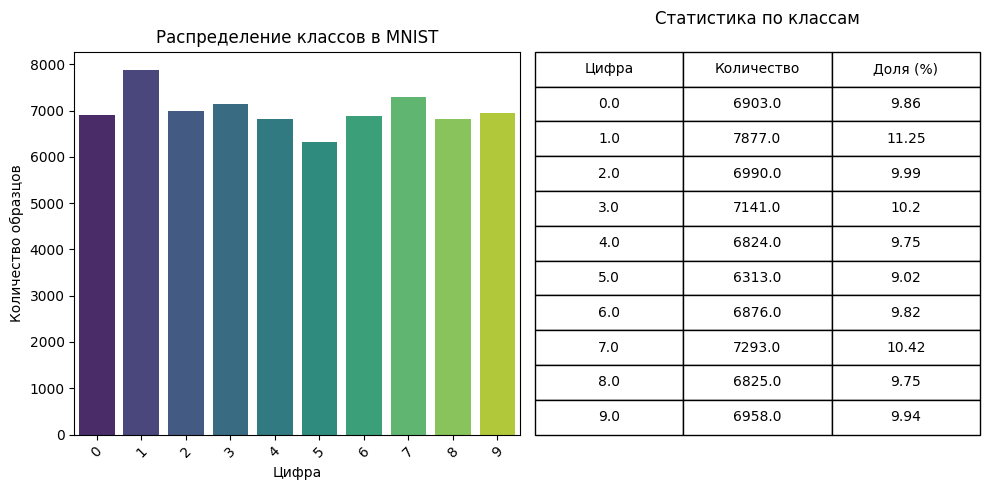

In [28]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.countplot(x=y, palette='viridis')
plt.title('Распределение классов в MNIST', fontsize=12)
plt.xlabel('Цифра')
plt.ylabel('Количество образцов')
plt.xticks(rotation=45)

class_counts = pd.Series(y).value_counts().sort_index()
stats_table = pd.DataFrame({
    'Цифра': class_counts.index,
    'Количество': class_counts.values,
    'Доля (%)': (class_counts.values / len(y) * 100).round(2)
})

plt.subplot(1, 2, 2)
plt.axis('off')
table = plt.table(
    cellText=stats_table.values,
    colLabels=stats_table.columns,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)
plt.title('Статистика по классам', fontsize=12, pad=20)

plt.tight_layout()
plt.show()

#### Снижение размерности

In [29]:
sample_size = 3000
indices = np.random.choice(X.shape[0], sample_size, replace=False)
X_sample = X[indices]
y_sample = y[indices]

In [30]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

##### PCA

In [31]:
start_time = time.time()
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
pca_time = time.time() - start_time
print(pca_time)

0.35256099700927734


In [32]:
print(np.sum(pca.explained_variance_ratio_))

0.11010291909264153


##### t-SNE на сырых данных

In [12]:
start_time = time.time()
tsne = TSNE(
    n_components=2,
    perplexity=30,
    max_iter=1000,
    random_state=42,
    verbose=1
)
X_tsne = tsne.fit_transform(X_scaled)
tsne_time = time.time() - start_time
print(tsne_time)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 3000 samples in 0.007s...
[t-SNE] Computed neighbors for 3000 samples in 0.767s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3000
[t-SNE] Computed conditional probabilities for sample 2000 / 3000
[t-SNE] Computed conditional probabilities for sample 3000 / 3000
[t-SNE] Mean sigma: 6.590589
[t-SNE] KL divergence after 250 iterations with early exaggeration: 79.322044
[t-SNE] KL divergence after 1000 iterations: 1.372349
71.48883867263794


##### Сначала PCA, потом t-SNE

In [13]:
pca_50 = PCA(n_components=50)
X_pca50 = pca_50.fit_transform(X_scaled)

In [14]:
start_time = time.time()
tsne_pca = TSNE(
    n_components=2,
    perplexity=30,
    max_iter=1000,
    random_state=42,
    verbose=1
)
X_tsne_pca = tsne_pca.fit_transform(X_pca50)
tsne_pca_time = time.time() - start_time
print(tsne_pca_time)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 3000 samples in 0.001s...
[t-SNE] Computed neighbors for 3000 samples in 0.333s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3000
[t-SNE] Computed conditional probabilities for sample 2000 / 3000
[t-SNE] Computed conditional probabilities for sample 3000 / 3000
[t-SNE] Mean sigma: 4.898118
[t-SNE] KL divergence after 250 iterations with early exaggeration: 77.897766
[t-SNE] KL divergence after 1000 iterations: 1.307855
36.09302067756653


##### График

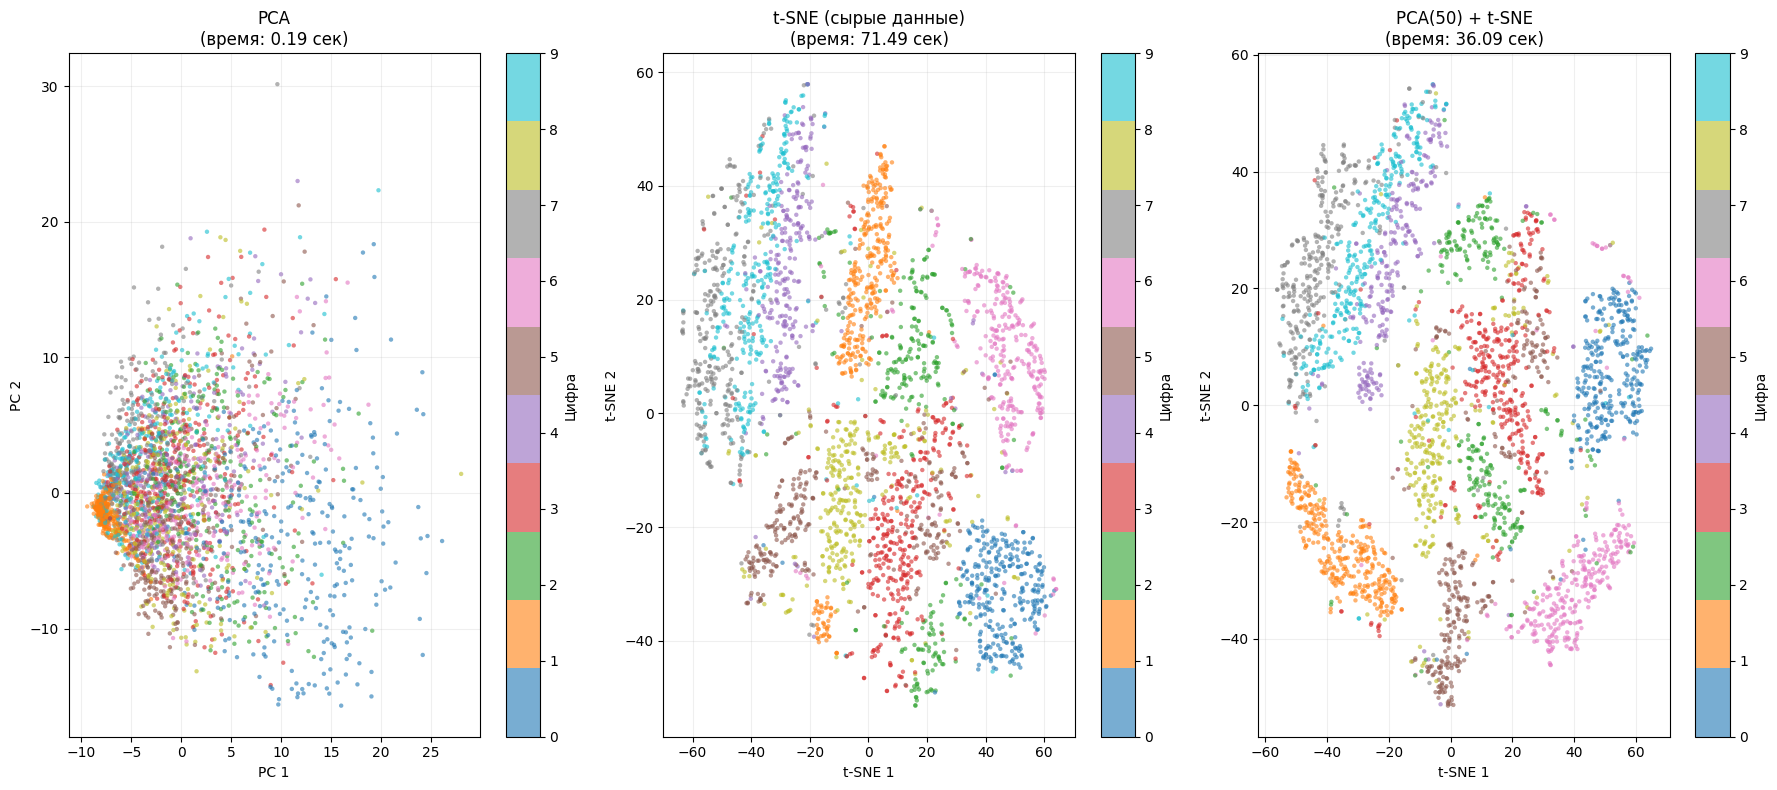

In [15]:
plt.figure(figsize=(18, 8))

# PCA
plt.subplot(1, 3, 1)
scatter1 = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y_sample,
    cmap='tab10',
    alpha=0.6,
    s=10,
    edgecolors='none'
)
plt.colorbar(scatter1, label='Цифра')
plt.title(f'PCA\n(время: {pca_time:.2f} сек)')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.grid(alpha=0.2)

# t-SNE
plt.subplot(1, 3, 2)
scatter2 = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=y_sample,
    cmap='tab10',
    alpha=0.6,
    s=10,
    edgecolors='none'
)
plt.colorbar(scatter2, label='Цифра')
plt.title(f't-SNE (сырые данные)\n(время: {tsne_time:.2f} сек)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.grid(alpha=0.2)

# PCA + t-SNE
plt.subplot(1, 3, 3)
scatter3 = plt.scatter(
    X_tsne_pca[:, 0], X_tsne_pca[:, 1],
    c=y_sample,
    cmap='tab10',
    alpha=0.6,
    s=10,
    edgecolors='none'
)
plt.colorbar(scatter3, label='Цифра')
plt.title(f'PCA(50) + t-SNE\n(время: {tsne_pca_time:.2f} сек)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### UMAP

In [19]:
import umap

In [20]:
start_time = time.time()
umap_reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='euclidean',
    random_state=42,
    verbose=False
)
X_umap = umap_reducer.fit_transform(X_pca50)
umap_time = time.time() - start_time
print(umap_time)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


19.739694118499756


Text(0.65, 0.7, 'Параметры UMAP:\nn_components=2\nn_neighbors=15\nmin_dist=0.1\nrandom_state=42')

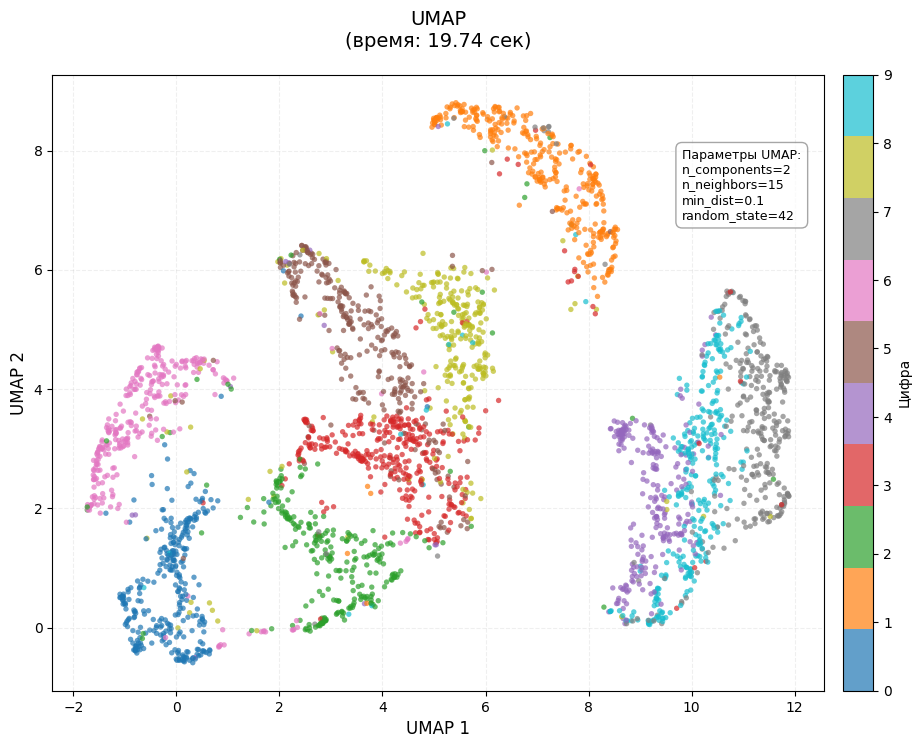

In [21]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    X_umap[:, 0], X_umap[:, 1],
    c=y_sample,
    cmap='tab10',
    alpha=0.7,
    s=15,
    edgecolors='none'
)

plt.colorbar(scatter, label='Цифра', pad=0.02)
plt.title(f'UMAP\n'
          f'(время: {umap_time:.2f} сек)',
          fontsize=14, pad=20)
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)
plt.grid(alpha=0.2, linestyle='--')

plt.figtext(0.65, 0.7,
            f'Параметры UMAP:\n'
            f'n_components=2\n'
            f'n_neighbors={umap_reducer.n_neighbors}\n'
            f'min_dist={umap_reducer.min_dist}\n'
            f'random_state=42',
            fontsize=9,
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray', boxstyle='round,pad=0.5'))